# Student Performance Prediction
**AMML + NNDL Mini Project**

This notebook loads the included student dataset, trains traditional machine-learning models and an ANN, compares their results, and lets you try a prediction.

> Note: The bundled dataset is synthetic and is intended for learning and demonstration only. Do not use these predictions for real academic decisions.

## 1. Install the required packages
Run this cell once if the packages are not already installed.

In [1]:
%pip -q install numpy pandas scikit-learn matplotlib joblib

## 2. Load the dataset
Keep this notebook in the same project folder as the `data` folder. If the CSV is not found, the cell will let you upload it.

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

DATA_FILE = Path("data/student_performance.csv")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

if not DATA_FILE.exists():
    try:
        from google.colab import files
        uploaded = files.upload()
        csv_name = next((name for name in uploaded if name.lower().endswith(".csv")), None)
        if csv_name is None:
            raise FileNotFoundError("Please upload student_performance.csv.")
        DATA_FILE = Path(csv_name)
    except ImportError:
        raise FileNotFoundError(
            "Dataset not found. Run this notebook from the project folder "
            "or place student_performance.csv in a data folder."
        )

df = pd.read_csv(DATA_FILE)
display(df.head())
print("Dataset shape:", df.shape)

Saving student_performance.csv to student_performance.csv


,study_hours_per_day,attendance_percentage,previous_exam_score,assignment_average,sleep_hours_per_night,extracurricular_hours_per_week,final_score
0,4.0,66.1,61.3,87.6,7.1,1.8,80.0
1,1.8,76.2,82.7,100.0,7.7,1.4,84.5
2,4.7,87.0,72.2,54.5,7.1,2.5,79.1
3,5.0,80.8,57.5,94.4,8.2,2.2,81.2
4,0.4,74.2,55.0,75.0,6.6,0.0,56.4


Dataset shape: (1200, 7)


## 3. Prepare the data
The target is `final_score`; the other six columns are input features.

In [3]:
FEATURES = [
    "study_hours_per_day",
    "attendance_percentage",
    "previous_exam_score",
    "assignment_average",
    "sleep_hours_per_night",
    "extracurricular_hours_per_week",
]
TARGET = "final_score"

missing = set(FEATURES + [TARGET]) - set(df.columns)
if missing:
    raise ValueError(f"Dataset is missing columns: {sorted(missing)}")

df = df.dropna(subset=FEATURES + [TARGET])
X = df[FEATURES]
y = df[TARGET]

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print(f"Training rows: {len(X_train)}")
print(f"Testing rows: {len(X_test)}")

Training rows: 960
Testing rows: 240


## 4. Train AMML and NNDL models

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=6, min_samples_leaf=8, random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=250, max_depth=10, min_samples_leaf=3,
        random_state=42, n_jobs=-1
    ),
    "ANN (MLP)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", MLPRegressor(
            hidden_layer_sizes=(64, 32), activation="relu", solver="adam",
            alpha=0.001, learning_rate_init=0.001, max_iter=700,
            early_stopping=True, validation_fraction=0.15,
            random_state=42
        ))
    ])
}

metrics_rows = []
predictions = {}

for name, model in models.items():
    print("Training", name)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred
    metrics_rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

metrics = pd.DataFrame(metrics_rows).sort_values("RMSE")
display(metrics.round(3))
metrics.to_csv(OUTPUT_DIR / "model_metrics.csv", index=False)

for name, model in models.items():
    slug = name.lower().replace(" ", "_").replace("(", "").replace(")", "")
    joblib.dump(model, OUTPUT_DIR / f"{slug}.joblib")

print("Trained models and metrics saved in the outputs folder.")

Training Linear Regression
Training Decision Tree
Training Random Forest
Training ANN (MLP)


,Model,MAE,RMSE,R2
0,Linear Regression,5.598,6.939,0.524
3,ANN (MLP),5.639,7.045,0.509
2,Random Forest,5.808,7.269,0.477
1,Decision Tree,6.705,8.274,0.323


Trained models and metrics saved in the outputs folder.


## 5. Plot model comparison

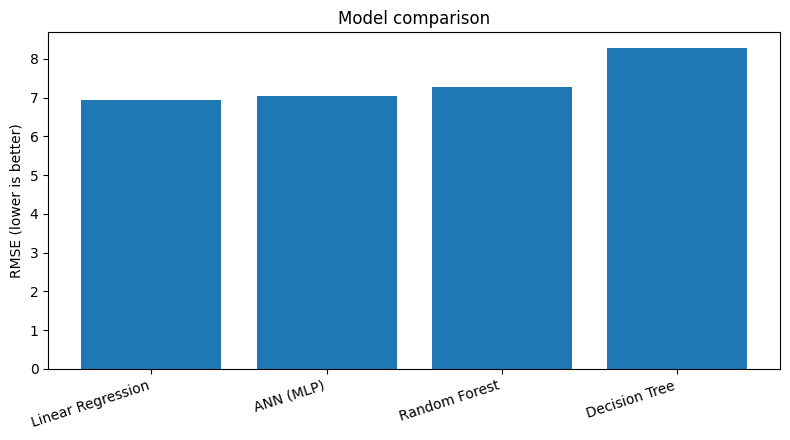

In [5]:
plt.figure(figsize=(8, 4.5))
plt.bar(metrics["Model"], metrics["RMSE"])
plt.ylabel("RMSE (lower is better)")
plt.title("Model comparison")
plt.xticks(rotation=18, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "model_rmse_comparison.png", dpi=150)
plt.show()

## 6. Plot the ANN training loss

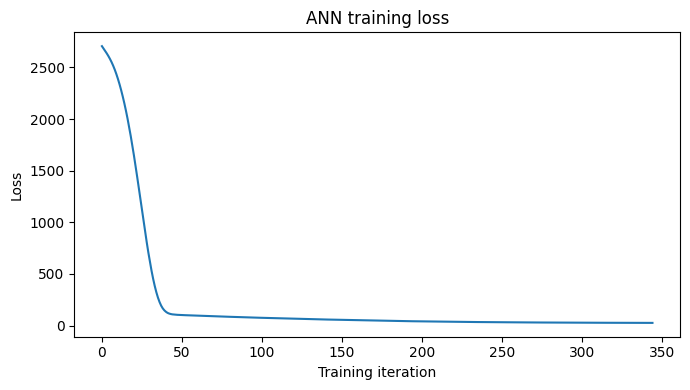

In [6]:
ann = models["ANN (MLP)"].named_steps["model"]
plt.figure(figsize=(7, 4))
plt.plot(ann.loss_curve_)
plt.xlabel("Training iteration")
plt.ylabel("Loss")
plt.title("ANN training loss")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "ann_training_loss.png", dpi=150)
plt.show()

## 7. Actual vs predicted scores

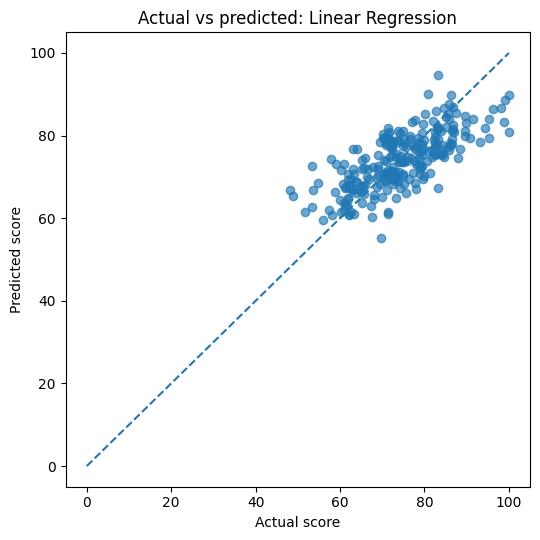

Best model by RMSE in this run: Linear Regression


In [7]:
best_name = metrics.iloc[0]["Model"]
plt.figure(figsize=(5.5, 5.5))
plt.scatter(y_test, predictions[best_name], alpha=0.65)
plt.plot([0, 100], [0, 100], linestyle="--")
plt.xlabel("Actual score")
plt.ylabel("Predicted score")
plt.title(f"Actual vs predicted: {best_name}")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "actual_vs_predicted.png", dpi=150)
plt.show()
print("Best model by RMSE in this run:", best_name)

## 8. Try a prediction
Change the example values if you want. The score is a model estimate, not a guaranteed result.

In [8]:
sample_student = pd.DataFrame([{
    "study_hours_per_day": 4.0,
    "attendance_percentage": 85.0,
    "previous_exam_score": 70.0,
    "assignment_average": 75.0,
    "sleep_hours_per_night": 7.0,
    "extracurricular_hours_per_week": 2.0
}])

selected_model = "ANN (MLP)"  # Change to another model name if desired
predicted_score = float(models[selected_model].predict(sample_student)[0])
predicted_score = max(0.0, min(100.0, predicted_score))
print(f"Model: {selected_model}")
print(f"Estimated final score: {predicted_score:.1f} / 100")

Model: ANN (MLP)
Estimated final score: 73.9 / 100


## Conclusion
This notebook demonstrates data preparation, supervised regression, model evaluation, and an artificial neural network. The supplied dataset is synthetic; the results are for classroom demonstration only.